# 03. Pollutant Dynamics Audit

I use this notebook to check the four pollutant equations separately from the Study 3 environment. All inputs are hypothetical and chosen for easy inspection. They are not measured regional values or calibrated parameters.

The checks look for expected mathematical behavior, such as mass balance and nonnegative values. Passing them shows that the equations work under these assumptions.

## Scope and assumptions

- PM2.5 is calculated as annual exposure from emissions and a hypothetical source-receptor matrix. It is not carried over as a mass stock.
- CO2 is one shared atmospheric perturbation calculated from emissions cohorts and the Joos response. This example starts with zero anomaly and leaves out external emissions.
- Nitrate-N is a hypothetical catchment compartment with fixed water volume and annual input, outflow, transformation, and treatment fractions.
- Lead is split between mobile and immobilized soil pools. Immobilization moves lead between pools; erosion and excavation remove lead from this compartment.

Each step is one year. None of the hypothetical values here should be used as regional estimates.

In [ ]:
import math
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
YEARS = 40
REGIONS = ("Northeast", "Midwest", "South", "West")

# Hypothetical annual PM2.5 emissions (t/year) and background exposure (ug/m3).
pm_emissions = {"Northeast": 10.0, "Midwest": 12.0, "South": 11.0, "West": 9.0}
pm_background = {"Northeast": 4.0, "Midwest": 5.0, "South": 6.0, "West": 4.0}

# This hypothetical matrix maps source emissions to receptor exposure.
pm_source_receptor = pd.DataFrame([[0.08, 0.02, 0.01, 0.01],
                                   [0.02, 0.07, 0.02, 0.01],
                                   [0.01, 0.03, 0.08, 0.02],
                                   [0.01, 0.01, 0.02, 0.07]],
                                   index=REGIONS, columns=REGIONS)


# Hypothetical catchment values: mass in kg N and annual load in kg N/year.
nitrate_initial_mass = 1000.0
nitrate_annual_load = 120.0
nitrate_outflow_fraction = 0.20
nitrate_transformation_fraction = 0.10
nitrate_treatment_fraction = 0.05
nitrate_water_volume_m3 = 1_000_000.0

# Hypothetical lead mass in kg Pb in a defined soil compartment.
lead_initial_total = 500.0
lead_initial_mobile_fraction = 0.10
lead_annual_input = 20.0
lead_input_mobile_fraction = 0.50
lead_remobilization_fraction = 0.02
lead_immobilization_fraction = 0.15
lead_erosion_fraction = 0.03
lead_excavation_fraction = 0.01

## 1. PM2.5: emissions and annual exposure

For each receptor r and year t:

C[r,t] = C_background[r] + sum_s K[r,s] * E[s,t]

Rows of K represent receptor regions, and columns represent source regions. Each K value maps source emissions to exposure at a receptor. This example uses hypothetical coefficients and leaves out atmospheric chemistry and weather. It recalculates exposure each year instead of carrying a concentration stock forward.

In [3]:
def calculate_pm25_exposure(emissions, background, source_receptor, emission_multiplier=1.0):
    exposure = background.copy()

    for receptor in source_receptor.index:
        source_contribution = 0.0

        for source in source_receptor.columns:
            contribution = source_receptor.loc[receptor, source] * emissions[source]
            contribution *= emission_multiplier
            source_contribution += contribution

        exposure[receptor] += source_contribution

    return exposure

In [ ]:
pm25_exposure = calculate_pm25_exposure(pm_emissions, pm_background, pm_source_receptor)
pm25_rows = []

for region in REGIONS:
    row = {"receptor": region, "annual emissions (hypothetical t/year)": pm_emissions[region],
        "background (hypothetical ug/m3)": pm_background[region], "modeled annual exposure (hypothetical ug/m3)": pm25_exposure[region]}
    pm25_rows.append(row)

pm25_results = pd.DataFrame(pm25_rows)
display(pm_source_receptor)
display(pm25_results.round(3))

In [ ]:
zero_emissions = {}

for region in REGIONS:
    zero_emissions[region] = 0.0

zero_exposure = calculate_pm25_exposure(zero_emissions, pm_background, pm_source_receptor)
double_exposure = calculate_pm25_exposure(pm_emissions, pm_background, pm_source_receptor, 2.0)

zero_check = True
double_check = True
nonnegative_check = True

for region in REGIONS:
    zero_difference = abs(zero_exposure[region] - pm_background[region])
    original_contribution = pm25_exposure[region] - pm_background[region]
    doubled_contribution = double_exposure[region] - pm_background[region]
    double_difference = abs(doubled_contribution - 2 * original_contribution)

    if zero_difference >= 1e-12:
        zero_check = False

    if double_difference >= 1e-12:
        double_check = False

    if pm25_exposure[region] < pm_background[region]:
        nonnegative_check = False

pm25_check_rows = []
pm25_check_rows.append({"check": "Zero emissions return background", "passes": zero_check})
pm25_check_rows.append({"check": "Doubling emissions doubles source contribution", "passes": double_check})
pm25_check_rows.append({"check": "Exposure stays at or above background", "passes": nonnegative_check})

pm25_checks = pd.DataFrame(pm25_check_rows)
display(pm25_checks)

### PM2.5 results

With the hypothetical coefficients, annual exposure is 5.24 ug/m3 in the Northeast, 6.35 in the Midwest, 7.52 in the South, and 5.07 in the West. The checks show that the calculation responds linearly to emissions and returns background when emissions are zero.

## 2. CO2: shared atmospheric response

Each annual emissions pulse contributes emission * R(age) to the shared atmospheric perturbation. The test starts with no atmospheric anomaly and assigns each pulse an age in years. The remaining amount not in the atmosphere is counted as transfer out; the notebook does not divide it between land and ocean sinks.

In [ ]:
CO2_RESPONSE_COMPONENTS = ((0.2173, None), (0.2240, 394.4), (0.2824, 36.54), (0.2763, 4.304))

In [7]:
def co2_response_fraction(age_years, components=CO2_RESPONSE_COMPONENTS):
    remaining_fraction = 0.0

    for coefficient, time_constant in components:
        if time_constant is None:
            remaining_fraction += coefficient
        else:
            remaining_fraction += coefficient * math.exp(-age_years / time_constant)

    return remaining_fraction

In [ ]:
def simulate_co2_cohorts(annual_emissions, components=CO2_RESPONSE_COMPONENTS):
    cohorts = []
    rows = []
    cumulative_emissions = 0.0

    for year, annual_emission in enumerate(annual_emissions):
        aged_cohorts = []

        for age, mass in cohorts:
            aged_cohorts.append((age + 1, mass))

        cohorts = aged_cohorts
        cohorts.append((0, annual_emission))
        cumulative_emissions += annual_emission

        atmospheric_perturbation = 0.0

        for age, mass in cohorts:
            remaining_fraction = co2_response_fraction(age, components)
            atmospheric_perturbation += mass * remaining_fraction

        cumulative_transfer_out = cumulative_emissions - atmospheric_perturbation
        row = {"year": year + 1, "cumulative emissions": cumulative_emissions, "atmospheric perturbation": atmospheric_perturbation,"cumulative transfer out": cumulative_transfer_out}
        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
co2_annual_emissions = [100.0] * YEARS
co2_trajectory = simulate_co2_cohorts(co2_annual_emissions)
display(co2_trajectory.tail().round(3))

In [10]:
co2_response_ages = [0, 1, 5, 10, 20, 40, 100, 500]
co2_response_values = []

for age in co2_response_ages:
    response = co2_response_fraction(age)
    co2_response_values.append(response)

co2_response_table = pd.DataFrame({"age (years)": co2_response_ages, "fraction of pulse remaining": co2_response_values})
display(co2_response_table.round(4))

,age (years),fraction of pulse remaining
0,0,1.0000
1,1,0.9345
2,5,0.7712
3,10,0.6775
4,20,0.5962
5,40,0.5142
6,100,0.4094
7,500,0.2803


In [11]:
age_zero_check = abs(co2_response_fraction(0) - 1.0) < 1e-12
nonnegative_check = True
decreasing_check = True
mass_balance_check = True

for age in range(0, 501):
    response = co2_response_fraction(age)

    if response < 0:
        nonnegative_check = False

    if age < 500:
        next_response = co2_response_fraction(age + 1)

        if next_response > response:
            decreasing_check = False

for _, row in co2_trajectory.iterrows():
    emissions = row["cumulative emissions"]
    atmospheric = row["atmospheric perturbation"]
    transfer = row["cumulative transfer out"]
    difference = abs(emissions - atmospheric - transfer)

    if difference >= 1e-8:
        mass_balance_check = False

co2_check_rows = []
co2_check_rows.append({"check": "Age-zero pulse response is one", "passes": age_zero_check})
co2_check_rows.append({"check": "Response is nonnegative", "passes": nonnegative_check})
co2_check_rows.append({"check": "Response never increases with age", "passes": decreasing_check})
co2_check_rows.append({"check": "Emissions balance with atmosphere and transfer out", "passes": mass_balance_check})

co2_checks = pd.DataFrame(co2_check_rows)
display(co2_checks)

,check,passes
0,Age-zero pulse response is one,True
1,Response is nonnegative,True
2,Response never increases with age,True
3,Emissions balance with atmosphere and transfer...,True


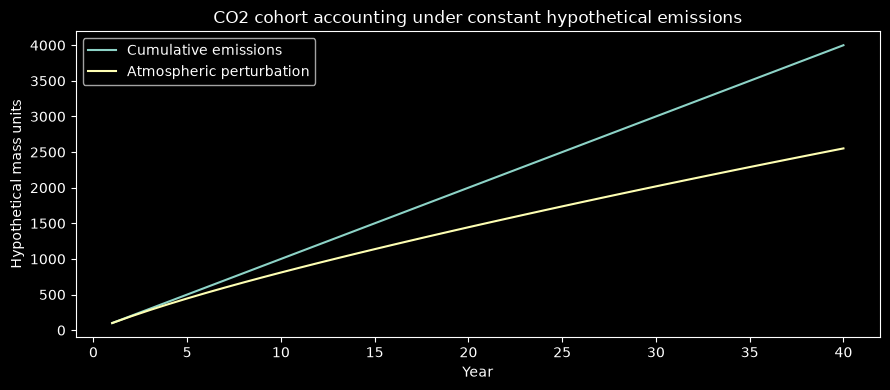

In [12]:
plt.figure(figsize=(9, 4))
plt.plot(co2_trajectory["year"], co2_trajectory["cumulative emissions"], label="Cumulative emissions")
plt.plot(co2_trajectory["year"], co2_trajectory["atmospheric perturbation"], label="Atmospheric perturbation")
plt.xlabel("Year")
plt.ylabel("Hypothetical mass units")
plt.title("CO2 cohort accounting under constant hypothetical emissions")
plt.legend()
plt.tight_layout()
plt.show()

### CO2 results

After 40 years of hypothetical emissions totaling 4,000 mass units, the model leaves 2,551.612 units in the atmospheric perturbation and counts 1,448.388 as transferred out. The pulse response falls from 1.0 at age zero to 0.2803 at age 500. These results illustrate the implemented impulse-response arithmetic; they do not validate real-world emissions, sinks, or a global starting concentration.

## 3. Nitrate-N: one catchment compartment

The example starts with nitrogen mass M and adds annual load L. It then accounts for outflow, transformation, and treatment as fractions of available mass M + L. The remainder becomes next year's mass.

The fractions must be nonnegative and add up to no more than one; otherwise a step could remove more mass than is available. Concentration is calculated from mass divided by fixed water volume, with the conversion from kg/m3 to mg/L.

In [13]:
def simulate_nitrate(years, initial_mass, annual_load, outflow_fraction, transformation_fraction, treatment_fraction, water_volume_m3):
    mass = initial_mass
    cumulative_load = 0.0
    cumulative_export = 0.0
    cumulative_transformation = 0.0
    cumulative_treatment = 0.0
    rows = []

    for year in range(1, years + 1):
        available_mass = mass + annual_load
        exported = outflow_fraction * available_mass
        transformed = transformation_fraction * available_mass
        treated = treatment_fraction * available_mass
        mass = available_mass - exported - transformed - treated

        cumulative_load += annual_load
        cumulative_export += exported
        cumulative_transformation += transformed
        cumulative_treatment += treated
        concentration_mg_l = mass / water_volume_m3 * 1000.0

        row = {
            "year": year,
            "mass (kg N)": mass,
            "concentration (mg N/L)": concentration_mg_l,
            "cumulative load": cumulative_load,
            "cumulative export": cumulative_export,
            "cumulative transformation": cumulative_transformation,
            "cumulative treatment": cumulative_treatment,
        }
        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
nitrate_trajectory = simulate_nitrate(YEARS, nitrate_initial_mass, nitrate_annual_load, nitrate_outflow_fraction, nitrate_transformation_fraction, nitrate_treatment_fraction, nitrate_water_volume_m3)

display(nitrate_trajectory.tail().round(3))

In [ ]:
nitrate_final = nitrate_trajectory.iloc[-1]
nitrate_balance_error = (nitrate_initial_mass + nitrate_final["cumulative load"] - nitrate_final["mass (kg N)"] - nitrate_final["cumulative export"] - nitrate_final["cumulative transformation"] - nitrate_final["cumulative treatment"])

In [16]:
removal_fractions = (nitrate_outflow_fraction, nitrate_transformation_fraction, nitrate_treatment_fraction)
fractions_in_range = True

for fraction in removal_fractions:
    if fraction < 0 or fraction > 1:
        fractions_in_range = False

fractions_sum_to_one_or_less = sum(removal_fractions) <= 1
mass_balance_check = abs(nitrate_balance_error) < 1e-8
mass_nonnegative_check = True

for mass in nitrate_trajectory["mass (kg N)"]:
    if mass < 0:
        mass_nonnegative_check = False

nitrate_final = nitrate_trajectory.iloc[-1]
expected_concentration = nitrate_final["mass (kg N)"] / nitrate_water_volume_m3 * 1000.0
concentration_difference = abs(nitrate_final["concentration (mg N/L)"] - expected_concentration)
concentration_conversion_check = concentration_difference < 1e-12

nitrate_check_rows = []
nitrate_check_rows.append({"check": "Removal fractions are within range", "passes": fractions_in_range})
nitrate_check_rows.append({"check": "Removal fractions sum to one or less", "passes": fractions_sum_to_one_or_less})
nitrate_check_rows.append({"check": "Mass balance closes", "passes": mass_balance_check})
nitrate_check_rows.append({"check": "Mass remains nonnegative", "passes": mass_nonnegative_check})
nitrate_check_rows.append({"check": "Concentration uses the stated volume conversion", "passes": concentration_conversion_check})

nitrate_checks = pd.DataFrame(nitrate_check_rows)
display(nitrate_checks)

,check,passes
0,Removal fractions are within range,True
1,Removal fractions sum to one or less,True
2,Mass balance closes,True
3,Mass remains nonnegative,True
4,Concentration uses the stated volume conversion,True


### Nitrate example result

With the selected load, removal fractions, and fixed water volume, the 40-year example ends at about 222.857 kg N, or 0.223 mg N/L. The mass balance includes the initial mass, added loads, remaining mass, export, transformation, and treatment. This is a controlled bookkeeping example, not a measured water system.

### Nitrate sensitivity

The table and graph vary input load, outflow, and transformation while keeping water volume fixed. In this example, a larger load increases final mass and a larger outflow lowers it. These are responses of the hypothetical catchment, not evidence-based parameter ranges or a real water-quality forecast.

In [ ]:
nitrate_sensitivity_rows = []
treatment_fraction = 0.05

for load_scale in (0.5, 1.0, 1.5):
    for outflow_fraction in (0.10, 0.20, 0.30):
        for transformation_fraction in (0.05, 0.10, 0.15):
            total_removal_fraction = outflow_fraction + transformation_fraction + treatment_fraction

            if total_removal_fraction <= 1:
                result = simulate_nitrate(YEARS, nitrate_initial_mass, nitrate_annual_load * load_scale, outflow_fraction, transformation_fraction, treatment_fraction, nitrate_water_volume_m3)

                final_result = result.iloc[-1]
                final_mass = final_result["mass (kg N)"]
                final_concentration = final_result["concentration (mg N/L)"]

                row = {"load scale": load_scale, "outflow fraction": outflow_fraction, "transformation fraction":transformation_fraction,
                    "final mass (kg N)": final_mass, "final concentration (mg N/L)": final_concentration}
                nitrate_sensitivity_rows.append(row)

nitrate_sensitivity = pd.DataFrame(nitrate_sensitivity_rows)
display(nitrate_sensitivity.round(3))

In [ ]:
reference_load_filter = nitrate_sensitivity["load scale"] == 1.0
reference_transformation_filter = nitrate_sensitivity["transformation fraction"] == 0.10
nitrate_reference = nitrate_sensitivity[reference_load_filter & reference_transformation_filter]
nitrate_reference = nitrate_reference.sort_values("outflow fraction")

load_comparison_filter = nitrate_sensitivity["outflow fraction"] == 0.20
load_comparison_filter &= nitrate_sensitivity["transformation fraction"] == 0.10
nitrate_load_comparison = nitrate_sensitivity[load_comparison_filter].sort_values("load scale")

load_direction_check = nitrate_load_comparison["final mass (kg N)"].is_monotonic_increasing
outflow_direction_check = nitrate_reference["final mass (kg N)"].is_monotonic_decreasing

nitrate_direction_rows = []
nitrate_direction_rows.append({"check": "Higher load increases final mass at fixed removal", "passes": load_direction_check})
nitrate_direction_rows.append({"check": "Higher outflow lowers final mass at fixed load", "passes": outflow_direction_check})

nitrate_direction_checks = pd.DataFrame(nitrate_direction_rows)
display(nitrate_direction_checks)

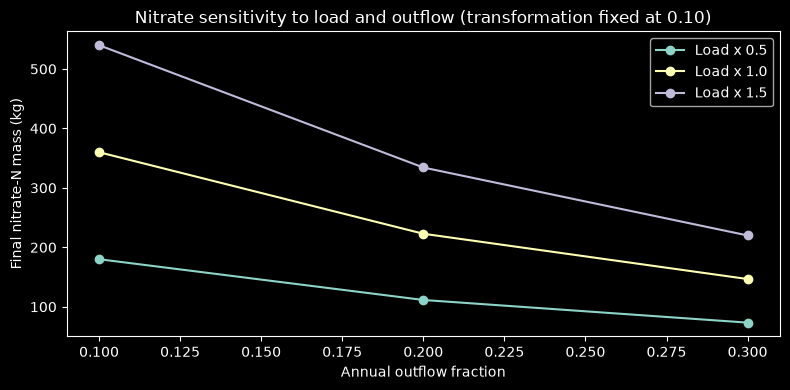

In [19]:
nitrate_plot_filter = nitrate_sensitivity["transformation fraction"] == 0.10
nitrate_sensitivity_plot = nitrate_sensitivity[nitrate_plot_filter]

plt.figure(figsize=(8, 4))

for load_scale in (0.5, 1.0, 1.5):
    load_filter = nitrate_sensitivity_plot["load scale"] == load_scale
    subset = nitrate_sensitivity_plot[load_filter]
    plt.plot(subset["outflow fraction"], subset["final mass (kg N)"],
             marker="o", label=f"Load x {load_scale}")

plt.xlabel("Annual outflow fraction")
plt.ylabel("Final nitrate-N mass (kg)")
plt.title("Nitrate sensitivity to load and outflow (transformation fixed at 0.10)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Lead: total and mobile soil pools

The example splits total lead into a mobile pool B and an immobilized pool I. New lead is split between pools; some immobilized lead can become mobile again, and some mobile lead can become immobilized. Erosion exports mobile lead, while excavation removes a share from both pools.

The mass check includes new inputs, erosion export, and excavation. Transfers between B and I do not count as removal from the soil compartment.

In [ ]:
def simulate_lead(years, initial_total, initial_mobile_fraction, annual_input, input_mobile_fraction, remobilization_fraction,                    immobilization_fraction, erosion_fraction, excavation_fraction):

    mobile = initial_total * initial_mobile_fraction
    immobilized = initial_total - mobile
    cumulative_input = 0.0
    cumulative_erosion = 0.0
    cumulative_excavation = 0.0
    rows = []

    for year in range(1, years + 1):
        new_mobile = annual_input * input_mobile_fraction
        new_immobilized = annual_input - new_mobile
        mobile += new_mobile
        immobilized += new_immobilized
        cumulative_input += annual_input

        remobilized = immobilized * remobilization_fraction
        immobilized -= remobilized
        mobile += remobilized

        newly_immobilized = mobile * immobilization_fraction
        mobile -= newly_immobilized
        immobilized += newly_immobilized

        eroded = mobile * erosion_fraction
        mobile -= eroded
        cumulative_erosion += eroded

        excavated_mobile = mobile * excavation_fraction
        excavated_immobilized = immobilized * excavation_fraction
        excavated = excavated_mobile + excavated_immobilized
        mobile -= excavated_mobile
        immobilized -= excavated_immobilized
        cumulative_excavation += excavated

        row = {
            "year": year,
            "mobile Pb (kg)": mobile,
            "immobilized Pb (kg)": immobilized,
            "total Pb (kg)": mobile + immobilized,
            "cumulative input (kg)": cumulative_input,
            "cumulative erosion export (kg)": cumulative_erosion,
            "cumulative excavation (kg)": cumulative_excavation,
        }
        rows.append(row)

    return pd.DataFrame(rows)

In [ ]:
lead_trajectory = simulate_lead(YEARS, lead_initial_total, lead_initial_mobile_fraction, lead_annual_input, lead_input_mobile_fraction,lead_remobilization_fraction, lead_immobilization_fraction, lead_erosion_fraction, lead_excavation_fraction)

lead_final = lead_trajectory.iloc[-1]

lead_balance_error = (lead_initial_total + lead_final["cumulative input (kg)"] - lead_final["total Pb (kg)"] - lead_final["cumulative erosion export (kg)"] - lead_final["cumulative excavation (kg)"])

display(lead_trajectory.tail().round(3))

In [22]:
pool_balance_errors = lead_trajectory["total Pb (kg)"] - lead_trajectory["mobile Pb (kg)"] - lead_trajectory["immobilized Pb (kg)"]
pool_balance_check = True
nonnegative_pools_check = True

for error in pool_balance_errors:
    if abs(error) >= 1e-10:
        pool_balance_check = False

for _, row in lead_trajectory.iterrows():
    if row["mobile Pb (kg)"] < 0 or row["immobilized Pb (kg)"] < 0:
        nonnegative_pools_check = False

mobility_only_result = simulate_lead(1, lead_initial_total, lead_initial_mobile_fraction, lead_annual_input, lead_input_mobile_fraction,lead_remobilization_fraction, lead_immobilization_fraction, 0.0, 0.0)

expected_lead_total = lead_initial_total + lead_annual_input
actual_lead_total = mobility_only_result.iloc[0]["total Pb (kg)"]
immobilization_check = abs(actual_lead_total - expected_lead_total) < 1e-10
lead_mass_balance_check = abs(lead_balance_error) < 1e-8

lead_check_rows = []
lead_check_rows.append({"check": "Total lead equals mobile plus immobilized pools", "passes": pool_balance_check})
lead_check_rows.append({"check": "Mass balance closes with export and excavation counted", "passes": lead_mass_balance_check})
lead_check_rows.append({"check": "Both pools remain nonnegative", "passes": nonnegative_pools_check})
lead_check_rows.append({"check": "Immobilization alone does not remove total lead", "passes": immobilization_check})

lead_checks = pd.DataFrame(lead_check_rows)
display(lead_checks)

,check,passes
0,Total lead equals mobile plus immobilized pools,True
1,Mass balance closes with export and excavation...,True
2,Both pools remain nonnegative,True
3,Immobilization alone does not remove total lead,True


### Lead example result

In the saved 40-year example, the soil compartment ends with 111.230 kg mobile Pb and 781.534 kg immobilized Pb, for 892.764 kg total. Erosion exports 116.678 kg and excavation removes 290.558 kg. Immobilization changes the mobile share; the mass balance closes only after the exports and excavation are counted.

### Lead sensitivity

The table and graph vary the initial mobile fraction and the remobilization and immobilization rates. In this hypothetical setup, more immobilization reduces the mobile pool. Because it reduces erosion, it also leaves more total lead in the soil compartment. The values are illustrative; actual mobility depends on soil conditions and how it is measured.

In [ ]:
lead_sensitivity_rows = []

for initial_mobile_fraction in (0.05, 0.10, 0.25):
    for remobilization_fraction in (0.00, 0.02, 0.05):
        for immobilization_fraction in (0.05, 0.15, 0.30):
            result = simulate_lead(YEARS, lead_initial_total, initial_mobile_fraction, lead_annual_input, lead_input_mobile_fraction,remobilization_fraction, immobilization_fraction, lead_erosion_fraction, lead_excavation_fraction)

            final = result.iloc[-1]
            row = {
                "initial mobile fraction": initial_mobile_fraction,
                "remobilization fraction": remobilization_fraction,
                "immobilization fraction": immobilization_fraction,
                "final mobile Pb (kg)": final["mobile Pb (kg)"],
                "final immobilized Pb (kg)": final["immobilized Pb (kg)"],
                "final total Pb (kg)": final["total Pb (kg)"],
            }
            lead_sensitivity_rows.append(row)

lead_sensitivity = pd.DataFrame(lead_sensitivity_rows)
display(lead_sensitivity.round(3))

In [ ]:
initial_mobile_filter = lead_sensitivity["initial mobile fraction"] == 0.10
remobilization_filter = lead_sensitivity["remobilization fraction"] == 0.02
lead_sensitivity_plot = lead_sensitivity[initial_mobile_filter & remobilization_filter]
lead_sensitivity_plot = lead_sensitivity_plot.sort_values("immobilization fraction")

mobile_direction_check = lead_sensitivity_plot["final mobile Pb (kg)"].is_monotonic_decreasing
total_direction_check = lead_sensitivity_plot["final total Pb (kg)"].is_monotonic_increasing

lead_direction_rows = []
lead_direction_rows.append({"check": "Higher immobilization lowers final mobile pool in this setup", "passes": mobile_direction_check})
lead_direction_rows.append({"check": "Higher immobilization retains more total lead by reducing erosion", "passes": total_direction_check})

lead_direction_checks = pd.DataFrame(lead_direction_rows)
display(lead_direction_checks)

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(lead_sensitivity_plot["immobilization fraction"], lead_sensitivity_plot["final mobile Pb (kg)"], marker="o", label="Mobile pool")

plt.plot(lead_sensitivity_plot["immobilization fraction"], lead_sensitivity_plot["final immobilized Pb (kg)"], marker="o", abel="Immobilized pool")

plt.plot(lead_sensitivity_plot["immobilization fraction"], lead_sensitivity_plot["final total Pb (kg)"], marker="o", label="Total Pb")

plt.xlabel("Annual immobilization fraction")
plt.ylabel("Final lead mass (kg)")
plt.title("Immobilization shifts lead pools but does not destroy lead")
plt.legend()
plt.tight_layout()
plt.show()